# CampusPulse — Data Preprocessing Notebook
---

**What this notebook does:**  
Takes each raw dataset from `data/raw/`, applies a series of clearly documented cleaning steps, and saves a clean CSV to `data/processed/`.

**Why preprocessing matters:**  
Real-world data is messy — wrong types, missing values, inconsistent labels, duplicate rows. Every decision made here directly affects every downstream analysis (statistics, clustering, machine learning). This notebook documents *what* was done and *why*, so the choices can be explained and reproduced.

**Datasets processed:**
| # | Dataset | Source | Raw File |
|---|---------|--------|----------|
| 1 | OpenML Student Lifestyle | Synthetic / OpenML 46752 | `dataset_.arff` |
| 2 | UCI Student Performance | Real — Portuguese schools, 2008 | `student-mat.csv`, `student-por.csv` |
| 3 | Kaggle Mental Health Survey | Real — Malaysian university, 2020 | `student_mental_health.csv` |

> **Key principle:** Each dataset is cleaned *independently* in its own schema.  
> We do **not** merge or compare raw values across datasets in this notebook.  
> That happens in `03_standardize.ipynb` using relative (percentile) measures only.


## 0 · Imports and Setup

> **What:** Load the libraries needed for this notebook.  
> **Why:** `pandas` handles tabular data, `numpy` for numeric ops, `scipy.io.arff` for the ARFF format (OpenML), `matplotlib`/`seaborn` for inline diagnostic plots.


In [7]:
import os
from pathlib import Path
import warnings

# Resolve the project root so relative data paths work from either the root or src/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Could not locate the project data/raw directory")
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# from scipy.io import arff
warnings.filterwarnings("ignore")

# Display settings — show all columns, clean float format
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="muted")

# Output directories
Path("data/processed").mkdir(parents=True, exist_ok=True)

print("✅ Setup complete")

✅ Setup complete


---
## 1 · OpenML Student Lifestyle Dataset

> **Source:** OpenML dataset ID 46752 · Synthetic data  
> **Population:** 2,000 simulated students  
> **File format:** ARFF (Attribute-Relation File Format) — used by Weka and OpenML  
> **Columns:** `Student_ID`, `Study_Hours_Per_Day`, `Sleep_Hours_Per_Day`, `Extracurricular_Hours_Per_Day`, `Social_Hours_Per_Day`, `Physical_Activity_Hours_Per_Day`, `GPA`, `Stress_Level`  

**Note on synthetic data:** Stress_Level in this dataset is *algorithmically derived* from the other columns during data generation — it is not a self-reported survey response. This means the stress↔lifestyle correlations here reflect the generation model's assumptions, not necessarily real student behaviour.


### 1.1 · Load Raw ARFF File

> **What:** `scipy.io.arff.loadarff()` reads ARFF files and returns a structured numpy array + metadata object.  
> **Why ARFF?** ARFF encodes both data and schema (column names, types, nominal values) in one file — commonly used by OpenML. Pandas cannot read it directly.  
> **Bytes issue:** String columns in ARFF are loaded as Python `bytes` objects (e.g. `b'Low'`). We must decode them to regular strings using `.str.decode("utf-8")`.


In [5]:
# # Load ARFF — returns (data_array, metadata)
# raw_data, meta = arff.loadarff("data/raw/dataset_.arff")
# df_ls_raw = pd.DataFrame(raw_data)

# print("Shape:", df_ls_raw.shape)
# print("\nColumn dtypes (before decode):")
# print(df_ls_raw.dtypes)
df=pd.read_csv("data/raw/student_lifestyle_dataset.csv")
df.head()



,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.900,3.800,8.700,2.800,1.800,2.990,Moderate
1,2,5.300,3.500,8.000,4.200,3.000,2.750,Low
2,3,5.100,3.900,9.200,1.200,4.600,2.670,Low
3,4,6.500,2.100,7.200,1.700,6.500,2.880,Moderate
4,5,8.100,0.600,6.500,2.200,6.600,3.510,High


In [ ]:
# # Decode byte-strings to regular Python strings
# for col in df_ls_raw.select_dtypes(["object"]).columns:
#     df_ls_raw[col] = df_ls_raw[col].str.decode("utf-8")

# print("First 5 rows after decode:")
# df_ls_raw.head()


### 1.2 · Initial Exploration (Before Cleaning)

> **What:** Get a statistical summary of the raw data.  
> **Why:** Before cleaning, you need to understand the data's range, distribution, and any obvious anomalies (e.g. negative hours, GPA > 4, missing values).  
> This is called **Exploratory Data Analysis (EDA)** and it *drives* the cleaning decisions — you don't clean blindly.


In [8]:
# Statistical summary of numeric columns
print("=== Numeric Summary ===")
print(df.describe().round(3))

print("\n=== Stress_Level value counts ===")
print(df["Stress_Level"].value_counts())

print("\n=== Missing values per column ===")
print(df.isnull().sum())


=== Numeric Summary ===
       Student_ID  Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  \
count    2000.000             2000.000                       2000.000   
mean     1000.500                7.476                          1.990   
std       577.495                1.424                          1.156   
min         1.000                5.000                          0.000   
25%       500.750                6.300                          1.000   
50%      1000.500                7.400                          2.000   
75%      1500.250                8.700                          3.000   
max      2000.000               10.000                          4.000   

       Sleep_Hours_Per_Day  Social_Hours_Per_Day  \
count             2000.000              2000.000   
mean                 7.501                 2.705   
std                  1.461                 1.689   
min                  5.000                 0.000   
25%                  6.200                 1.200   
50%   

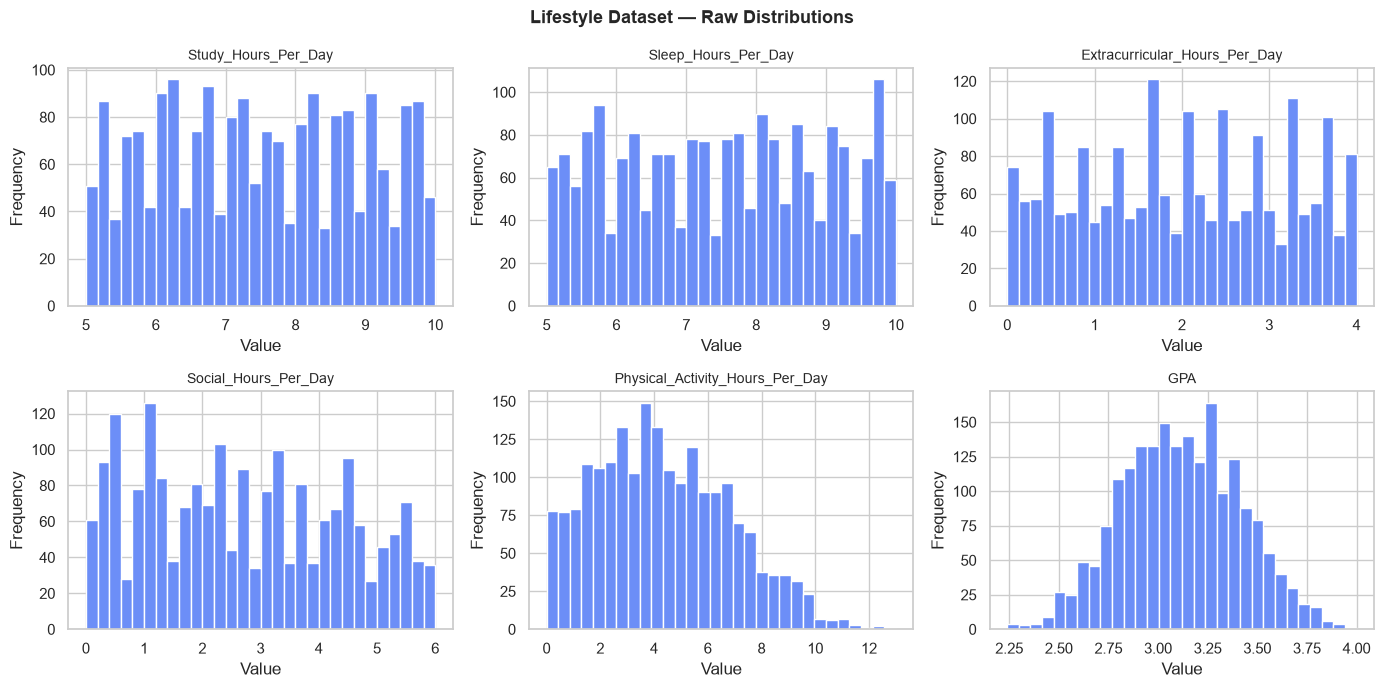

💾 Saved diagnostic plot


In [9]:
# Visual check — distributions of all numeric columns
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

numeric_cols = ["Study_Hours_Per_Day", "Sleep_Hours_Per_Day",
                "Extracurricular_Hours_Per_Day", "Social_Hours_Per_Day",
                "Physical_Activity_Hours_Per_Day", "GPA"]

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col].dropna(), bins=30, color="#6c8ef7", edgecolor="white")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

plt.suptitle("Lifestyle Dataset — Raw Distributions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("data/processed/ls_raw_distributions.png", dpi=120, bbox_inches="tight")
plt.show()
print("💾 Saved diagnostic plot")


### 1.3 · Cleaning Steps

#### Step A — Standardize column names to snake_case

> **What:** Convert all column names to lowercase with underscores.  
> **Why:** Python convention (`snake_case`) prevents bugs from case mismatches like `df['GPA']` vs `df['gpa']`. Consistent naming is essential when multiple datasets feed into one pipeline.


In [10]:
df_ls = df.copy()   # always work on a copy — keep raw intact

df_ls.columns = [c.lower().strip() for c in df_ls.columns]
print("Columns after rename:", df_ls.columns.tolist())


Columns after rename: ['student_id', 'study_hours_per_day', 'extracurricular_hours_per_day', 'sleep_hours_per_day', 'social_hours_per_day', 'physical_activity_hours_per_day', 'gpa', 'stress_level']


#### Step B — Drop non-analytical columns

> **What:** Remove `student_id`.  
> **Why:** Row identifiers have no predictive or analytical value. Including them in models or correlation analysis can cause spurious results (a model might 'learn' the ID instead of real patterns). IDs are also a privacy concern.


In [11]:
df_ls = df_ls.drop(columns=["student_id"], errors="ignore")
print("Columns after dropping ID:", df_ls.columns.tolist())


Columns after dropping ID: ['study_hours_per_day', 'extracurricular_hours_per_day', 'sleep_hours_per_day', 'social_hours_per_day', 'physical_activity_hours_per_day', 'gpa', 'stress_level']


#### Step C — Enforce correct data types

> **What:** Force numeric columns to float using `pd.to_numeric(..., errors='coerce')`.  
> **Why:** ARFF loading sometimes produces `float64` already, but explicit casting ensures any stray string values (e.g. `'?'` used as a missing marker in some ARFF files) become `NaN` rather than crashing downstream operations. `errors='coerce'` means "if it can't convert, make it NaN" — safe and auditable.


In [12]:
numeric_cols = ["study_hours_per_day", "sleep_hours_per_day",
                "extracurricular_hours_per_day", "social_hours_per_day",
                "physical_activity_hours_per_day", "gpa"]

df_ls[numeric_cols] = df_ls[numeric_cols].apply(pd.to_numeric, errors="coerce")

# Standardize Stress_Level to Title Case: 'low' → 'Low'
df_ls["stress_level"] = df_ls["stress_level"].str.strip().str.title()

print("Dtypes after cast:")
print(df_ls.dtypes)


Dtypes after cast:
study_hours_per_day                float64
extracurricular_hours_per_day      float64
sleep_hours_per_day                float64
social_hours_per_day               float64
physical_activity_hours_per_day    float64
gpa                                float64
stress_level                           str
dtype: object


#### Step D — Domain validation (range checks)

> **What:** Remove rows where values fall outside physically possible ranges.  
> **Why:** A GPA of 5.2 or sleep of −1 hours cannot be real — they are data entry errors or generation artifacts. Keeping them skews means, variances, and model weights.  
> These are called **domain constraints** — rules from the real world, not statistics.


In [ ]:
before = len(df_ls)

# Keep missing values for the imputation step; remove only observed values
# that violate the documented domain ranges.
gpa_valid = df_ls["gpa"].isna() | df_ls["gpa"].between(0, 4)
df_ls = df_ls[gpa_valid]

hour_cols = ["study_hours_per_day", "sleep_hours_per_day",
             "extracurricular_hours_per_day", "social_hours_per_day",
             "physical_activity_hours_per_day"]
for col in hour_cols:
    valid = df_ls[col].isna() | df_ls[col].between(0, 24)
    df_ls = df_ls[valid]

# The target stress category must be present and one of the documented labels.
valid_stress = {"Low", "Moderate", "High"}
df_ls = df_ls[df_ls["stress_level"].isin(valid_stress)]

after = len(df_ls)
print(f"Rows before domain validation: {before}")
print(f"Rows after domain validation: {after} (removed {before - after} invalid records)")
print("Missing numeric values are retained for the next imputation step.")

#### Step E — Handle missing values

> **What:** Check for NaN values and decide what to do with them.  
> **Why:** Missing values propagate silently — a mean computed on a column with NaNs will be wrong unless pandas drops them (which it does by default, but some functions don't). The key decision is: *drop row* vs *impute* vs *leave as NaN*.  
> - **Drop row:** when the key target variable (GPA, stress) is missing — a row without a label is useless for supervised tasks.  
> - **Impute:** when a feature is missing but the row is otherwise complete — impute with median for skewed data, mean for normal.  
> - **Leave as NaN:** when the column is not required for the current task.


In [ ]:
print("=== Missing values after domain validation ===")
print(df_ls.isnull().sum())
print(f"\nTotal rows: {len(df_ls)}")

# GPA and stress are the analysis targets in this notebook; records without
# either target cannot be used in the corresponding analyses.
before_targets = len(df_ls)
df_ls = df_ls.dropna(subset=["gpa", "stress_level"])
print(f"Rows removed because GPA/stress target is missing: {before_targets - len(df_ls)}")

# Impute missing predictor values only. GPA is a target and is not imputed.
feature_cols = [c for c in numeric_cols if c != "gpa"]
for col in feature_cols:
    n_missing = df_ls[col].isnull().sum()
    if n_missing > 0:
        median_val = df_ls[col].median()
        df_ls[col] = df_ls[col].fillna(median_val)
        print(f"  Imputed {n_missing} missing values in '{col}' with median={median_val:.3f}")

print("\nMissing values after target filtering and feature imputation:")
print(df_ls.isnull().sum())

#### Step F — Remove duplicate rows

> **What:** Use `df.drop_duplicates()` to remove exact duplicate rows.  
> **Why:** Duplicates inflate sample size artificially and bias frequency-based analyses (like association rules) and distance-based models (like K-Means). In survey data, a duplicate often means the form was submitted twice.


In [15]:
before = len(df_ls)
df_ls = df_ls.drop_duplicates()
after = len(df_ls)
print(f"Duplicates removed: {before - after}")
print(f"Final clean shape: {df_ls.shape}")


Duplicates removed: 0
Final clean shape: (2000, 7)


### 1.4 · Post-Cleaning Verification

> **What:** Re-inspect the data after cleaning to confirm the pipeline worked correctly.  
> **Why:** A cleaning step might silently remove too many rows (a bug in the range check), or leave behind nulls. Always verify — this is called a **data quality check** and is standard in production pipelines.


In [16]:
print("=== Final Lifestyle Dataset Summary ===")
print(f"Shape: {df_ls.shape}")
print("\nNumeric summary:")
print(df_ls.describe().round(3))
print("\nStress_Level distribution:")
print(df_ls["stress_level"].value_counts())


=== Final Lifestyle Dataset Summary ===
Shape: (2000, 7)

Numeric summary:
       study_hours_per_day  extracurricular_hours_per_day  \
count             2000.000                       2000.000   
mean                 7.476                          1.990   
std                  1.424                          1.156   
min                  5.000                          0.000   
25%                  6.300                          1.000   
50%                  7.400                          2.000   
75%                  8.700                          3.000   
max                 10.000                          4.000   

       sleep_hours_per_day  social_hours_per_day  \
count             2000.000              2000.000   
mean                 7.501                 2.705   
std                  1.461                 1.689   
min                  5.000                 0.000   
25%                  6.200                 1.200   
50%                  7.500                 2.600   
75%        

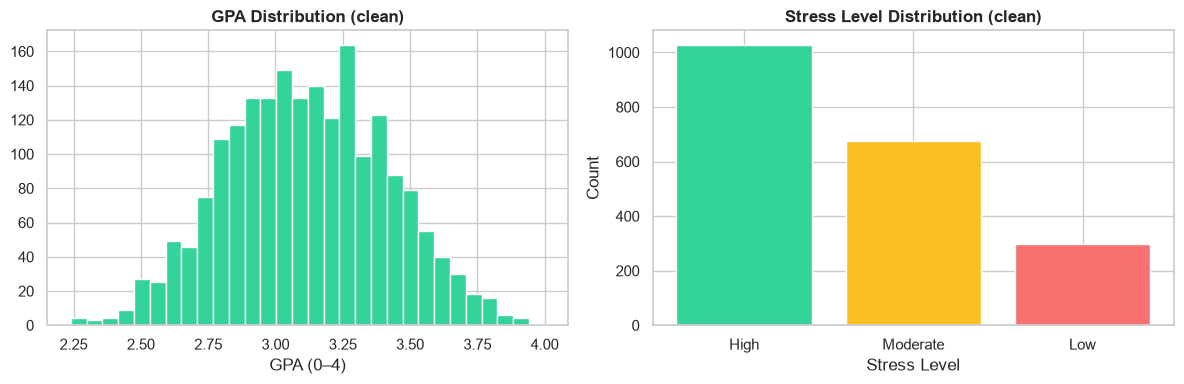

In [17]:
# Post-cleaning distribution — compare to pre-cleaning plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# GPA distribution
axes[0].hist(df_ls["gpa"], bins=30, color="#34d399", edgecolor="white")
axes[0].set_title("GPA Distribution (clean)", fontweight="bold")
axes[0].set_xlabel("GPA (0–4)")

# Stress Level bar chart
stress_counts = df_ls["stress_level"].value_counts()
axes[1].bar(stress_counts.index, stress_counts.values,
            color=["#34d399", "#fbbf24", "#f87171"], edgecolor="white")
axes[1].set_title("Stress Level Distribution (clean)", fontweight="bold")
axes[1].set_xlabel("Stress Level")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("data/processed/ls_clean_summary.png", dpi=120, bbox_inches="tight")
plt.show()


In [18]:
# Save clean file
df_ls.to_csv("data/processed/lifestyle_clean.csv", index=False)
print("Saved: data/processed/lifestyle_clean.csv")
print(f"   Shape: {df_ls.shape}")


Saved: data/processed/lifestyle_clean.csv
   Shape: (2000, 7)


---
## 2 · UCI Student Performance Dataset

> **Source:** UCI ML Repository — P. Cortez & A. Silva (2008)  
> **Population:** Real Portuguese secondary-school students (Math + Portuguese subjects)  
> **File format:** Semicolon-separated CSV (`;` not `,` — common in European datasets)  
> **Key columns:** `studytime` (1–4 code), `failures`, `absences`, `G1`/`G2`/`G3` (0–20), `Dalc`/`Walc` (alcohol), `age`, `sex`, `school`

**Critical context:** `studytime` is *not* hours — it is a categorical code:  
`1 = <2 hrs/week, 2 = 2–5 hrs/week, 3 = 5–10 hrs/week, 4 = >10 hrs/week`  
Treating it as a continuous number (1, 2, 3, 4) in a regression would be wrong.


### 2.1 · Load Raw Files

> **What:** Load both subject CSV files and combine them.  
> **Why two files?** The UCI dataset comes split by subject (Math vs Portuguese). Both have identical column schemas. We concatenate them and add a `subject` column to track origin — otherwise we'd lose information about which subject a grade refers to.


In [19]:
df_mat = pd.read_csv("data/raw/student-mat.csv", sep=";")
df_por = pd.read_csv("data/raw/student-por.csv", sep=";")

df_mat["subject"] = "math"
df_por["subject"] = "portuguese"

df_uc_raw = pd.concat([df_mat, df_por], ignore_index=True)

print(f"Math rows:       {len(df_mat)}")
print(f"Portuguese rows: {len(df_por)}")
print(f"Combined shape:  {df_uc_raw.shape}")
print("\nColumns:", df_uc_raw.columns.tolist())


Math rows:       395
Portuguese rows: 649
Combined shape:  (1044, 34)

Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'subject']


In [20]:
print("First 3 rows:")
df_uc_raw.head(3)


First 3 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,math
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,math
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,math


### 2.2 · Initial Exploration

In [21]:
print("=== Numeric Summary ===")
print(df_uc_raw[["age", "studytime", "failures", "absences",
                  "G1", "G2", "G3", "Dalc", "Walc"]].describe().round(2))

print("\n=== Missing values ===")
print(df_uc_raw.isnull().sum().to_string())

print("\n=== Categorical columns ===")
for col in ["school", "sex", "address", "Pstatus", "subject"]:
    print(f"  {col}: {df_uc_raw[col].unique()}")


=== Numeric Summary ===
           age  studytime  failures  absences       G1       G2       G3  \
count 1044.000   1044.000  1044.000  1044.000 1044.000 1044.000 1044.000   
mean    16.730      1.970     0.260     4.430   11.210   11.250   11.340   
std      1.240      0.830     0.660     6.210    2.980    3.290    3.860   
min     15.000      1.000     0.000     0.000    0.000    0.000    0.000   
25%     16.000      1.000     0.000     0.000    9.000    9.000   10.000   
50%     17.000      2.000     0.000     2.000   11.000   11.000   11.000   
75%     18.000      2.000     0.000     6.000   13.000   13.000   14.000   
max     22.000      4.000     3.000    75.000   19.000   19.000   20.000   

          Dalc     Walc  
count 1044.000 1044.000  
mean     1.490    2.280  
std      0.910    1.290  
min      1.000    1.000  
25%      1.000    1.000  
50%      1.000    2.000  
75%      2.000    3.000  
max      5.000    5.000  

=== Missing values ===
school        0
sex           0
a

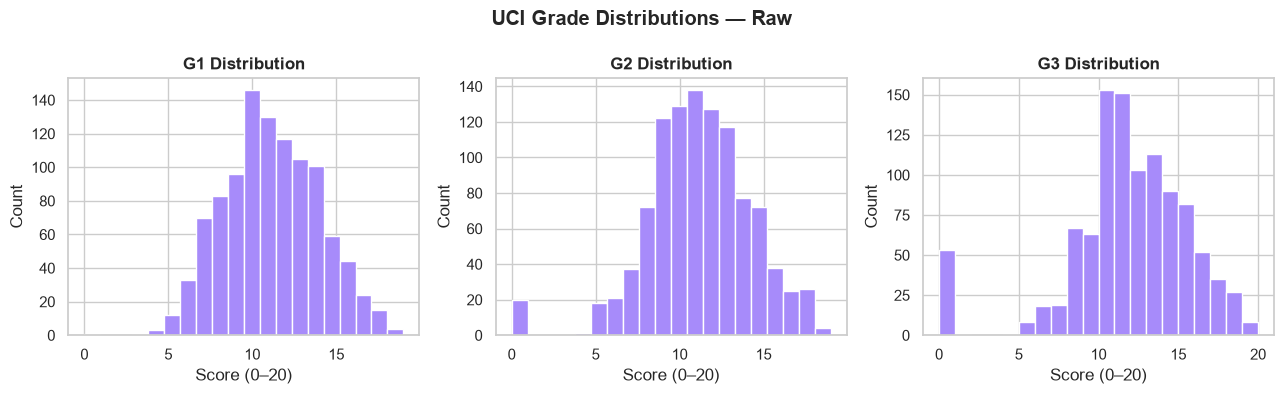

In [22]:
# Grade distribution: G1 (first period), G2 (second period), G3 (final)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for i, col in enumerate(["G1", "G2", "G3"]):
    axes[i].hist(df_uc_raw[col], bins=20, color="#a78bfa", edgecolor="white")
    axes[i].set_title(f"{col} Distribution", fontweight="bold")
    axes[i].set_xlabel("Score (0–20)")
    axes[i].set_ylabel("Count")
plt.suptitle("UCI Grade Distributions — Raw", fontweight="bold")
plt.tight_layout()
plt.savefig("data/processed/uci_raw_grades.png", dpi=120, bbox_inches="tight")
plt.show()


### 2.3 · Cleaning Steps

#### Step A — Standardize column names

In [23]:
df_uc = df_uc_raw.copy()
df_uc.columns = [c.lower().strip() for c in df_uc.columns]
print("Columns:", df_uc.columns.tolist())


Columns: ['school', 'sex', 'age', 'address', 'famsize', 'pstatus', 'medu', 'fedu', 'mjob', 'fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'dalc', 'walc', 'health', 'absences', 'g1', 'g2', 'g3', 'subject']


#### Step B — Enforce numeric types on grade columns

> **What:** Cast G1, G2, G3, age, studytime, failures, absences to numeric.  
> **Why:** Even though these look numeric, CSV loading can sometimes produce object dtype if a cell has an unexpected value. Explicit casting with `errors='coerce'` catches this safely.


In [24]:
grade_cols = ["g1", "g2", "g3"]
other_num  = ["age", "studytime", "failures", "absences",
               "dalc", "walc", "famrel", "freetime", "goout", "health"]

for col in grade_cols + other_num:
    df_uc[col] = pd.to_numeric(df_uc[col], errors="coerce")

print("Dtypes after cast:")
print(df_uc[grade_cols + other_num].dtypes)


Dtypes after cast:
g1           int64
g2           int64
g3           int64
age          int64
studytime    int64
failures     int64
absences     int64
dalc         int64
walc         int64
famrel       int64
freetime     int64
goout        int64
health       int64
dtype: object


#### Step C — Domain validation

> **What:** Remove rows with impossible values.  
> **Why:**  
> - Grades (G1, G2, G3) must be 0–20 (defined by the Portuguese grading system)  
> - Age 14–22 covers the realistic range for secondary school students  
> - `studytime` must be 1–4 (it is a categorical code, not a continuous value)  
> - `failures` must be 0–3 (dataset definition: 3 means 3 or more)


In [ ]:
before = len(df_uc)

# Preserve missing values for transparent downstream handling; filter only
# observed values outside the documented UCI domain ranges.
uci_ranges = {
    "g1": (0, 20), "g2": (0, 20), "g3": (0, 20),
    "age": (14, 22), "studytime": (1, 4), "failures": (0, 3),
    "dalc": (1, 5), "walc": (1, 5), "famrel": (1, 5),
    "freetime": (1, 5), "goout": (1, 5), "health": (1, 5)
}
for col, (lo, hi) in uci_ranges.items():
    valid = df_uc[col].isna() | df_uc[col].between(lo, hi)
    df_uc = df_uc[valid]

after = len(df_uc)
print(f"Rows removed by domain validation: {before - after}")
print(f"Remaining rows: {after}")
print("Missing values retained for explicit handling in derived features and analyses:")
print(df_uc[list(uci_ranges)].isna().sum().to_string())

#### Step D — Handle zero grades (G3 = 0)

> **What:** Investigate students with G3 = 0.  
> **Why:** In the UCI dataset, G3 = 0 often means the student dropped out or was absent for the final exam — not that they scored zero on the exam. Including these in a performance analysis conflates dropout behaviour with academic performance, which distorts results.  
> Decision: keep them but flag them — do not silently remove, as dropout is itself analytically interesting.


In [26]:
zero_g3 = df_uc[df_uc["g3"] == 0]
print(f"Students with G3 = 0: {len(zero_g3)}")
print(f"  → These may be dropouts or absentees, not zero scorers.")
print(f"  → We keep them but add a flag column for optional filtering.")

df_uc["possible_dropout"] = (df_uc["g3"] == 0).astype(int)
print(f"\n'possible_dropout' flag added. Value counts:")
print(df_uc["possible_dropout"].value_counts())


Students with G3 = 0: 53
  → These may be dropouts or absentees, not zero scorers.
  → We keep them but add a flag column for optional filtering.

'possible_dropout' flag added. Value counts:
possible_dropout
0    991
1     53
Name: count, dtype: int64


#### Step E — Build stress proxy from available columns

> **What:** UCI has no stress column. We construct a derived proxy score from related behavioural indicators.  
> **Why needed:** For cross-dataset comparison in the standardized table, we need a stress indicator for all datasets.  
> **Components used:**  
> - `dalc` (workday alcohol, 1–5) — alcohol use correlates with stress/coping  
> - `walc` (weekend alcohol, 1–5) — same  
> - `failures` (0–3) — academic failures are a strong stressor  
> - `freetime` inverted (1–5) — less free time → more academic pressure  
> **Important disclosure:** This proxy is a reasonable approximation, not a validated psychometric scale. Always label it as "derived stress proxy" in the dashboard, never as "self-reported stress".


In [ ]:
def compute_stress_proxy(df):
    """Researcher-defined behavioural/academic proxy; not a validated stress scale."""
    required = ["dalc", "walc", "failures", "freetime"]
    complete = df[required].notna().all(axis=1)
    score = pd.Series(np.nan, index=df.index, dtype=float)
    dalc_n = (df.loc[complete, "dalc"] - 1) / 4
    walc_n  = (df.loc[complete, "walc"] - 1) / 4
    fail_n  = df.loc[complete, "failures"] / 3
    free_n  = 1 - (df.loc[complete, "freetime"] - 1) / 4
    score.loc[complete] = (
        0.25 * dalc_n + 0.25 * walc_n + 0.35 * fail_n + 0.15 * free_n
    )
    return score

df_uc["stress_score_proxy"] = compute_stress_proxy(df_uc)

# Fixed cut-offs are researcher-defined categories, not empirical tertiles.
def label_stress(score):
    if pd.isna(score):
        return np.nan
    if score < 0.33:
        return "Low"
    elif score < 0.66:
        return "Moderate"
    return "High"

df_uc["stress_label_proxy"] = df_uc["stress_score_proxy"].apply(label_stress)

print("Behavioural and academic stress-proxy distribution (not a validated stress measure):")
print(df_uc["stress_label_proxy"].value_counts(dropna=False))
print(f"\nScore range: {df_uc['stress_score_proxy'].min():.3f} – {df_uc['stress_score_proxy'].max():.3f}")
print("Missing proxy scores (incomplete component data):", df_uc["stress_score_proxy"].isna().sum())

#### Step F — Remove duplicates

In [28]:
before = len(df_uc)
df_uc = df_uc.drop_duplicates()
print(f"Duplicates removed: {before - len(df_uc)}")
print(f"Final clean shape: {df_uc.shape}")


Duplicates removed: 0
Final clean shape: (1044, 37)


### 2.4 · Post-Cleaning Verification

=== Final UCI Dataset Summary ===
            g1       g2       g3      age  studytime  failures  absences
count 1044.000 1044.000 1044.000 1044.000   1044.000  1044.000  1044.000
mean    11.210   11.250   11.340   16.730      1.970     0.260     4.430
std      2.980    3.290    3.860    1.240      0.830     0.660     6.210
min      0.000    0.000    0.000   15.000      1.000     0.000     0.000
25%      9.000    9.000   10.000   16.000      1.000     0.000     0.000
50%     11.000   11.000   11.000   17.000      2.000     0.000     2.000
75%     13.000   13.000   14.000   18.000      2.000     0.000     6.000
max     19.000   19.000   20.000   22.000      4.000     3.000    75.000


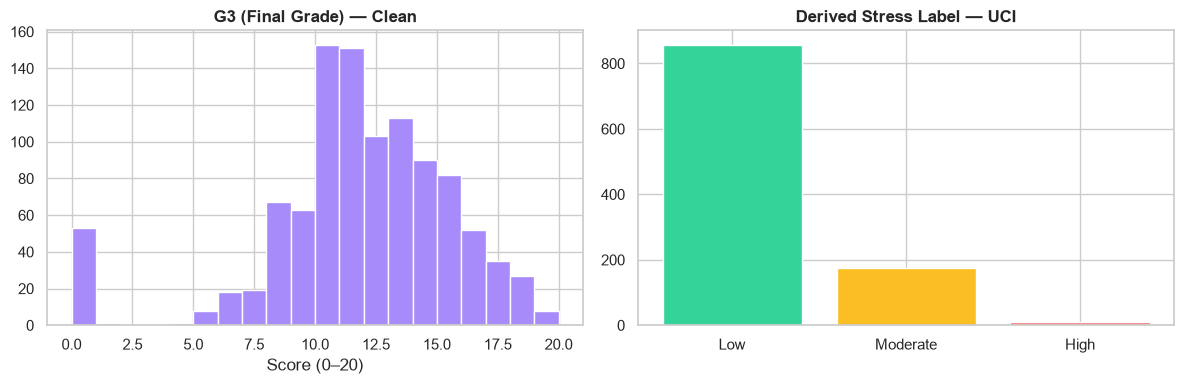

In [29]:
print("=== Final UCI Dataset Summary ===")
print(df_uc[["g1","g2","g3","age","studytime","failures","absences"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_uc["g3"], bins=20, color="#a78bfa", edgecolor="white")
axes[0].set_title("G3 (Final Grade) — Clean", fontweight="bold")
axes[0].set_xlabel("Score (0–20)")

stress_cts = df_uc["stress_label_proxy"].value_counts()
colors = {"Low": "#34d399", "Moderate": "#fbbf24", "High": "#f87171"}
axes[1].bar(stress_cts.index,
            stress_cts.values,
            color=[colors[k] for k in stress_cts.index],
            edgecolor="white")
axes[1].set_title("Derived Stress Label — UCI", fontweight="bold")

plt.tight_layout()
plt.savefig("data/processed/uci_clean_summary.png", dpi=120, bbox_inches="tight")
plt.show()


In [30]:
df_uc.to_csv("data/processed/uci_clean.csv", index=False)
print("✅ Saved: data/processed/uci_clean.csv")
print(f"   Shape: {df_uc.shape}")


✅ Saved: data/processed/uci_clean.csv
   Shape: (1044, 37)


---
## 3 · Kaggle Student Mental Health Survey

> **Source:** Kaggle — Student Mental Health survey, Malaysia 2020  
> **Population:** 101 Malaysian university students (self-selected survey respondents)  
> **File format:** Standard comma-separated CSV  
> **Key columns:** `CGPA` (range string like "3.00 – 3.49"), `Depression`, `Anxiety`, `Panic attack` (all Yes/No), `Age`, `Gender`, `Year of Study`

**Small sample warning:** With only 101 rows, this dataset has limited statistical power. Any analysis should be described as *exploratory* and results should not be generalized beyond this sample.


### 3.1 · Load Raw File

In [31]:
df_mh_raw = pd.read_csv("data/raw/Student Mental health.csv")
print(f"Shape: {df_mh_raw.shape}")
print("\nColumns:", df_mh_raw.columns.tolist())
print("\nFirst 3 rows:")
df_mh_raw.head(3)

Shape: (101, 11)

Columns: ['Timestamp', 'Choose your gender', 'Age', 'What is your course?', 'Your current year of Study', 'What is your CGPA?', 'Marital status', 'Do you have Depression?', 'Do you have Anxiety?', 'Do you have Panic attack?', 'Did you seek any specialist for a treatment?']

First 3 rows:


,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.000,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.000,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.000,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No


### 3.2 · Initial Exploration

In [32]:
print("=== Value counts for all columns ===")
for col in df_mh_raw.columns:
    print(f"\n-- {col} --")
    print(df_mh_raw[col].value_counts().to_string())


=== Value counts for all columns ===

-- Timestamp --
Timestamp
8/7/2020 12:39         3
8/7/2020 12:43         2
8/7/2020 13:13         2
8/7/2020 14:29         2
8/7/2020 14:43         2
8/7/2020 14:57         2
8/7/2020 15:14         2
8/7/2020 16:34         2
8/7/2020 12:02         1
8/7/2020 12:04         1
8/7/2020 12:05         1
8/7/2020 12:06         1
8/7/2020 12:13         1
8/7/2020 12:31         1
8/7/2020 12:32         1
8/7/2020 12:33         1
8/7/2020 12:35         1
8/7/2020 12:40         1
8/7/2020 12:41         1
8/7/2020 12:46         1
8/7/2020 12:52         1
8/7/2020 13:05         1
8/7/2020 13:07         1
8/7/2020 13:12         1
8/7/2020 13:15         1
8/7/2020 13:17         1
8/7/2020 13:29         1
8/7/2020 13:35         1
8/7/2020 13:41         1
8/7/2020 13:58         1
8/7/2020 14:05         1
8/7/2020 14:27         1
8/7/2020 14:31         1
8/7/2020 14:41         1
8/7/2020 14:45         1
8/7/2020 14:47         1
8/7/2020 14:56         1
8/7/2020 14

### 3.3 · Cleaning Steps

#### Step A — Rename verbose column headers

> **What:** The original headers are full survey question texts like "Do you have Depression?". We rename to short snake_case identifiers.  
> **Why:** Long column names cause bugs, wrap badly in notebooks, and make code hard to read. This is a very common first step when working with survey data.


In [33]:
df_mh = df_mh_raw.copy()

df_mh = df_mh.rename(columns={
    "Timestamp":                                         "timestamp",
    "Choose your gender":                                "gender",
    "Age":                                               "age",
    "What is your course?":                              "course",
    "Your current year of Study":                        "year_of_study",
    "What is your CGPA?":                                "cgpa_range",
    "Marital status":                                    "marital_status",
    "Do you have Depression?":                           "depression",
    "Do you have Anxiety?":                              "anxiety",
    "Do you have Panic attack?":                         "panic_attack",
    "Did you seek any specialist for a treatment?":      "sought_treatment",
})

print("Renamed columns:", df_mh.columns.tolist())


Renamed columns: ['timestamp', 'gender', 'age', 'course', 'year_of_study', 'cgpa_range', 'marital_status', 'depression', 'anxiety', 'panic_attack', 'sought_treatment']


#### Step B — Drop non-analytical columns

In [34]:
# Timestamp has no analytical value for this project
df_mh = df_mh.drop(columns=["timestamp"], errors="ignore")
print("Columns after drop:", df_mh.columns.tolist())


Columns after drop: ['gender', 'age', 'course', 'year_of_study', 'cgpa_range', 'marital_status', 'depression', 'anxiety', 'panic_attack', 'sought_treatment']


#### Step C — Standardize categorical values

> **What:** Fix inconsistent casing in `year_of_study` (e.g. "year 1" vs "Year 1") and standardize `gender`.  
> **Why:** `"year 1"` and `"Year 1"` are different strings — groupby operations would create separate groups for them, silently splitting the data. This is one of the most common silent bugs in data analysis.


In [35]:
# Standardize year_of_study: "year 1", "Year 1", "YEAR 1" → "Year 1"
df_mh["year_of_study"] = df_mh["year_of_study"].str.strip().str.title()
print("Year of Study values:", df_mh["year_of_study"].unique())

# Standardize gender
df_mh["gender"] = df_mh["gender"].str.strip().str.title()
print("Gender values:", df_mh["gender"].unique())

# Standardize Yes/No columns
yn_cols = ["depression", "anxiety", "panic_attack", "sought_treatment"]
for col in yn_cols:
    df_mh[col] = df_mh[col].str.strip().str.title()
print("\nDepression values:", df_mh["depression"].unique())


Year of Study values: <StringArray>
['Year 1', 'Year 2', 'Year 3', 'Year 4']
Length: 4, dtype: str
Gender values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str

Depression values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str


#### Step D — Parse CGPA range string to numeric midpoint

> **What:** Convert range strings like `"3.00 - 3.49"` to their numeric midpoint `3.245`.  
> **Why:** CGPA is stored as a range (a common privacy technique in surveys — respondents reveal a band, not an exact number). To use it in any quantitative analysis, we need a single number.  
> **Why midpoint?** It's the best unbiased estimate when only a range is known — assuming a uniform distribution within the band.  
> **Important:** The midpoint is an approximation — always note this in your report.


In [36]:
def parse_cgpa_range(s):
    """
    Convert a CGPA range string to its numeric midpoint.
    Examples:
        "3.00 - 3.49" → 3.245
        "3.50 - 4.00" → 3.750
        "2.50 - 2.99" → 2.745
    Returns None (NaN) if the string cannot be parsed.
    """
    if pd.isna(s):
        return None
    parts = str(s).split("-")
    try:
        lo = float(parts[0].strip())
        hi = float(parts[1].strip())
        return round((lo + hi) / 2, 4)
    except (ValueError, IndexError):
        return None

df_mh["cgpa_midpoint"] = df_mh["cgpa_range"].apply(parse_cgpa_range)

print("CGPA conversion check:")
print(df_mh[["cgpa_range", "cgpa_midpoint"]].drop_duplicates().sort_values("cgpa_midpoint"))


CGPA conversion check:
      cgpa_range  cgpa_midpoint
43      0 - 1.99          0.995
35   2.00 - 2.49          2.245
8    2.50 - 2.99          2.745
0    3.00 - 3.49          3.245
6   3.50 - 4.00           3.750
5    3.50 - 4.00          3.750


#### Step E — Convert Yes/No to binary integers (0/1)

> **What:** Map `"Yes"` → `1` and `"No"` → `0` for the four binary survey columns.  
> **Why:** Machine learning models and correlation functions require numeric input. Binary 0/1 encoding for Yes/No is the standard approach (called **dummy encoding** for two-category variables).  
> Using `.map()` is preferred over `.replace()` here because it returns `NaN` for any unexpected value (rather than silently keeping it), making data quality issues visible.


In [37]:
yn_map = {"Yes": 1, "No": 0}
for col in ["depression", "anxiety", "panic_attack", "sought_treatment"]:
    df_mh[col] = df_mh[col].map(yn_map)

# Check for any unmapped values (would show as NaN)
print("Binary column NaN counts (should be 0 if all values were Yes/No):")
print(df_mh[["depression", "anxiety", "panic_attack", "sought_treatment"]].isnull().sum())

print("\nSample of converted columns:")
print(df_mh[["depression", "anxiety", "panic_attack"]].head(5))


Binary column NaN counts (should be 0 if all values were Yes/No):
depression          0
anxiety             0
panic_attack        0
sought_treatment    0
dtype: int64

Sample of converted columns:
   depression  anxiety  panic_attack
0           1        0             1
1           0        1             0
2           1        1             1
3           1        0             0
4           0        0             0


#### Step F — Age validation and missing value handling

In [ ]:
df_mh["age"] = pd.to_numeric(df_mh["age"], errors="coerce")
before = len(df_mh)

# Retain missing ages for transparent reporting; remove only observed ages
# outside the broad screening range used in this project.
valid_age = df_mh["age"].isna() | df_mh["age"].between(17, 35)
df_mh = df_mh[valid_age]
print(f"Rows removed by age validation: {before - len(df_mh)}")
print("Rows with missing age retained:", df_mh["age"].isna().sum())

# CGPA is needed for academic-percentile analysis, so exclude missing CGPA only
# from the cleaned analysis dataset and report the number explicitly.
before_cgpa = len(df_mh)
df_mh = df_mh.dropna(subset=["cgpa_midpoint"])
print(f"Rows removed because CGPA midpoint is missing: {before_cgpa - len(df_mh)}")

before_dupes = len(df_mh)
df_mh = df_mh.drop_duplicates()
print(f"Duplicate rows removed: {before_dupes - len(df_mh)}")
print(f"Final shape: {df_mh.shape}")

#### Step G — Compute composite stress score

> **What:** Create a `stress_score` (0–1) from the three binary mental health flags.  
> **Why:** This dataset has direct mental health indicators, unlike the others. A composite score allows cross-dataset comparison on a common 0–1 axis. The score is simply the proportion of positive flags out of 3.


In [ ]:
mh_cols = ["depression", "anxiety", "panic_attack"]

# Do not let pandas' default skipna=True treat unanswered items as No.
# Compute the indicator score only when all three responses are available.
complete_mh = df_mh[mh_cols].notna().all(axis=1)
df_mh["mental_health_indicator_score"] = np.nan
df_mh.loc[complete_mh, "mental_health_indicator_score"] = (
    df_mh.loc[complete_mh, mh_cols].sum(axis=1) / len(mh_cols)
)

def classify_mental_health_indicators(score):
    if pd.isna(score):
        return np.nan
    if score == 0:
        return "0 indicators"
    if score < 1:
        return "1–2 indicators"
    return "3 indicators"

df_mh["mental_health_indicator_category"] = (
    df_mh["mental_health_indicator_score"].apply(classify_mental_health_indicators)
)

print("Mental-health indicator category distribution (not a stress classification):")
print(df_mh["mental_health_indicator_category"].value_counts(dropna=False))
print("\nRows with incomplete indicator responses:", (~complete_mh).sum())
print("The score counts three self-reported indicators; it is not a validated stress scale.")

### 3.4 · Post-Cleaning Verification

In [ ]:
print("=== Final Mental Health Dataset Summary ===")
print(df_mh.describe().round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# CGPA distribution
axes[0].hist(df_mh["cgpa_midpoint"].dropna(), bins=10, color="#f97316", edgecolor="white")
axes[0].set_title("CGPA Midpoint Distribution", fontweight="bold")
axes[0].set_xlabel("CGPA (0–4 approx.)")

# Mental health flags
mh_rates = df_mh[["depression", "anxiety", "panic_attack"]].mean() * 100
axes[1].bar(["Depression", "Anxiety", "Panic Attack"],
            mh_rates.values,
            color=["#f87171", "#fbbf24", "#a78bfa"],
            edgecolor="white")
axes[1].set_title("Mental Health Prevalence (%)", fontweight="bold")
axes[1].set_ylabel("% of students")
axes[1].set_ylim(0, 100)

# Mental-health indicator count category (not a stress level)
indicator_ct = df_mh["mental_health_indicator_category"].value_counts()
indicator_colors = {"0 indicators":"#34d399", "1–2 indicators":"#fbbf24", "3 indicators":"#f87171"}
axes[2].bar(indicator_ct.index, indicator_ct.values,
            color=[indicator_colors[k] for k in indicator_ct.index], edgecolor="white")
axes[2].set_title("Self-Reported Mental-Health Indicators", fontweight="bold")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("data/processed/mh_clean_summary.png", dpi=120, bbox_inches="tight")
plt.show()


In [41]:
df_mh.to_csv("data/processed/mental_health_clean.csv", index=False)
print("✅ Saved: data/processed/mental_health_clean.csv")
print(f"   Shape: {df_mh.shape}")


✅ Saved: data/processed/mental_health_clean.csv
   Shape: (100, 13)


---
## 4 · Preprocessing Summary

> **What:** Final audit across all three clean datasets.  
> **Why:** A summary table is useful for your report and confirms the pipeline ran correctly end-to-end.


In [ ]:
# Reload all three clean files (verifies the save worked correctly)
df_ls_check = pd.read_csv("data/processed/lifestyle_clean.csv")
df_uc_check = pd.read_csv("data/processed/uci_clean.csv")
df_mh_check = pd.read_csv("data/processed/mental_health_clean.csv")

summary = pd.DataFrame({
    "Dataset":        ["Lifestyle", "UCI Performance", "Mental Health"],
    "Rows":           [len(df_ls_check), len(df_uc_check), len(df_mh_check)],
    "Columns":        [df_ls_check.shape[1], df_uc_check.shape[1], df_mh_check.shape[1]],
    "Academic Score": ["gpa (0–4)", "g3 (0–20)", "cgpa_midpoint (0–4 approx.)"],
    "Stress Column":  ["stress_level (direct)", "stress_label_proxy (derived)", "mental_health_indicator_category (derived; not stress)"],
    "Null cells":     [df_ls_check.isnull().sum().sum(),
                       df_uc_check.isnull().sum().sum(),
                       df_mh_check.isnull().sum().sum()],
})

print(summary.to_string(index=False))
print("\n✅ All 3 datasets cleaned and saved to data/processed/")
print("   Next: run 03_analytics.ipynb to generate exploratory analysis outputs")


---
## What Each Cleaning Step Does — Quick Reference

| Step | Technique | Why It Matters |
|------|-----------|---------------|
| Decode bytes | `.str.decode("utf-8")` | ARFF files encode strings as bytes |
| snake_case columns | `.lower().strip()` | Prevents case-mismatch bugs |
| Drop IDs | `.drop(columns=...)` | IDs have no predictive value |
| Type casting | `pd.to_numeric(..., errors='coerce')` | Converts bad values to NaN safely |
| Range checks | `.between(lo, hi)` | Removes physically impossible values |
| Target null drop | `.dropna(subset=[target])` | Unlabelled rows are useless for ML |
| Median imputation | `.fillna(median)` | Robust to outliers, better than mean imputation |
| Duplicate removal | `.drop_duplicates()` | Prevents artificial sample inflation |
| String standardize | `.str.strip().str.title()` | Fixes silent group-split bugs in groupby |
| CGPA parse | custom midpoint function | Only safe way to quantify a range string |
| Binary encoding | `.map({"Yes":1,"No":0})` | Required for ML, standard for binary surveys |
| Stress proxy | weighted composite | Enables cross-dataset comparison where no direct column exists |

> **Remember for your viva:** Every cleaning decision should be *justifiable from the data's domain context* — not just mechanical. Explain *why* the range is 0–4 for GPA, *why* G3=0 might mean dropout, and *why* the stress proxy uses those specific weights.
